In [1]:
from lib_linear_probing import *
from deep_models.vae_train import *
from deep_models.vae import *
import torch
from deep_models.data import S00MILDataset, make_splits, load_folds
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np
import torch 
import pandas as pd
from sklearn.manifold import TSNE

In [2]:
dev_path = "/dmj/fizmed/mmarzec/licencjat_neuro/DL-NS/split_data/one_site/splits/s00_developmental.npz"
split_k = 7
num_workers = 2

In [3]:
developamental_folds = load_folds(dev_path)
_, train_idx, val_idx, test_idx = next(split for split in make_splits(developamental_folds) if split[0] == split_k)
print(f"train={len(train_idx)}  val={len(val_idx)}  test={len(test_idx)}")

train=1085  val=132  test=136


In [4]:
trainset = S00MILDataset(train_idx, max_instances=150, train=True, return_cond=True)
valset = S00MILDataset(val_idx, max_instances=150, train=False, return_cond=True)
testset = S00MILDataset(test_idx, max_instances=150, train=False, return_cond=True)


loader_kw = dict(batch_size=10, num_workers=num_workers, pin_memory=True) # type: ignore
trainloader = DataLoader(trainset, shuffle=True, **loader_kw)  # type: ignore
valloader = DataLoader(valset, shuffle=False, **loader_kw) # type: ignore
testloader = DataLoader(testset, shuffle=False, **loader_kw) # type: ignore

In [5]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
LATENT_DIM = 64

In [6]:
raw_tr, y_train, cond_tr = extract_raw_from_loader(trainloader)
raw_va, y_val,   cond_va = extract_raw_from_loader(valloader)
raw_te, y_test,  cond_te = extract_raw_from_loader(testloader)

raw_splits  = {"train": raw_tr,  "val": raw_va,  "test": raw_te}
cond_splits = {"train": cond_tr, "val": cond_va, "test": cond_te}

### 1. Baseline: Flattened off-diagonal raw inputs (5 * 17 * 16 = 1360 dims)


In [7]:
bags = {"raw_offdiag": {s: flatten_offdiag_bags(raw_splits[s]) for s in ("train", "val", "test")}}

### 2. Baseline: PCA on flattened off-diagonal raw inputs (64 dims, matching VAE latent_dim)

In [8]:
bags["pca"] = pca_bags(bags["raw_offdiag"], n_components=LATENT_DIM, seed=0)

### 3. Random ConvVAE (initialized with init_model, NO training)

In [9]:
torch.manual_seed(0)
vae_rand = SparseConvVAE(
    latent=64,
    alpha=0.1,
    cond_dim=2,
    cond_in_encoder=True,
).to(device)
init_model(vae_rand, trainloader)  # Same Xavier/He init as before training
vae_rand.eval()

bags["vae_random_mu"] = {
    s: embed_raw_bags(vae_rand, raw_splits[s], cond_bags=cond_splits[s], device=device)
    for s in ("train", "val", "test")
}

### 4. Trained ConvVAE

In [10]:
path = f"best_scvae_fold{split_k}.pt"
vae_trained = SparseConvVAE(
    latent=64,
    alpha=0.1,
    cond_dim=2,
    cond_in_encoder=True,
).to(device)
state_dict = torch.load(path, map_location=device, weights_only=True)
vae_trained.load_state_dict(state_dict)
vae_trained.eval()

bags["vae_trained_mu"] = {
    s: embed_raw_bags(vae_trained, raw_splits[s], cond_bags=cond_splits[s], device=device)
    for s in ("train", "val", "test")
}

### 5. Trained VAE - active dimensions (threshold for mu_variance 0.1)

In [11]:
mask = active_mask(bags["vae_trained_mu"]["train"], thr=0.1)
print(f"Trained VAE active units: {mask.sum()} / {LATENT_DIM}")
bags["vae_trained_mu_active"] = select_dims(bags["vae_trained_mu"], mask)

Trained VAE active units: 31 / 64


In [12]:
representations = ["raw_offdiag", "pca", "vae_random_mu", "vae_trained_mu", "vae_trained_mu_active"]

In [13]:
rows, artifacts = run_nn_probes(bags=bags,
                                representations=representations,
                                y_train=y_train,
                                y_val=y_val,
                                y_test=y_test,
                                return_artifacts=True,
                                abmil_variants={"ABMIL_linear": None, "ABMIL_h64": 64})
df = pd.DataFrame(rows)

[raw_offdiag] LinearBagProbe  val AUC = 0.697  epoch = 59  test AUC = 0.771
[raw_offdiag] LinearInstanceProbeBagLabels_soft  val AUC = 0.690  epoch = 32  test AUC = 0.756
[raw_offdiag] LinearInstanceProbeBagLabels_vote  val AUC = 0.692  epoch = 32  test AUC = 0.763
[raw_offdiag] ABMIL_linear  val AUC = 0.665  epoch = 7  test AUC = 0.692
[raw_offdiag] ABMIL_h64  val AUC = 0.686  epoch = 15  test AUC = 0.738
[pca] LinearBagProbe  val AUC = 0.681  epoch = 22  test AUC = 0.710
[pca] LinearInstanceProbeBagLabels_soft  val AUC = 0.699  epoch = 32  test AUC = 0.648
[pca] LinearInstanceProbeBagLabels_vote  val AUC = 0.714  epoch = 32  test AUC = 0.675
[pca] ABMIL_linear  val AUC = 0.709  epoch = 6  test AUC = 0.740
[pca] ABMIL_h64  val AUC = 0.724  epoch = 18  test AUC = 0.688
[vae_random_mu] LinearBagProbe  val AUC = 0.551  epoch = 1  test AUC = 0.504
[vae_random_mu] LinearInstanceProbeBagLabels_soft  val AUC = 0.534  epoch = 69  test AUC = 0.554
[vae_random_mu] LinearInstanceProbeBagLabels_v

## Visualization in 2-dims

In [14]:
embeddings_2d = {rep: TSNE(n_components=2, init="pca", learning_rate="auto", random_state=0).fit_transform(artifacts[rep]["X_val"]) for rep in representations}

In [15]:
val_sizes = np.array([len(b) for b in bags["vae_trained_mu"]["val"]])
exam_ids = np.repeat(np.arange(len(val_sizes)), val_sizes)
window_labels = np.repeat(y_val, val_sizes)

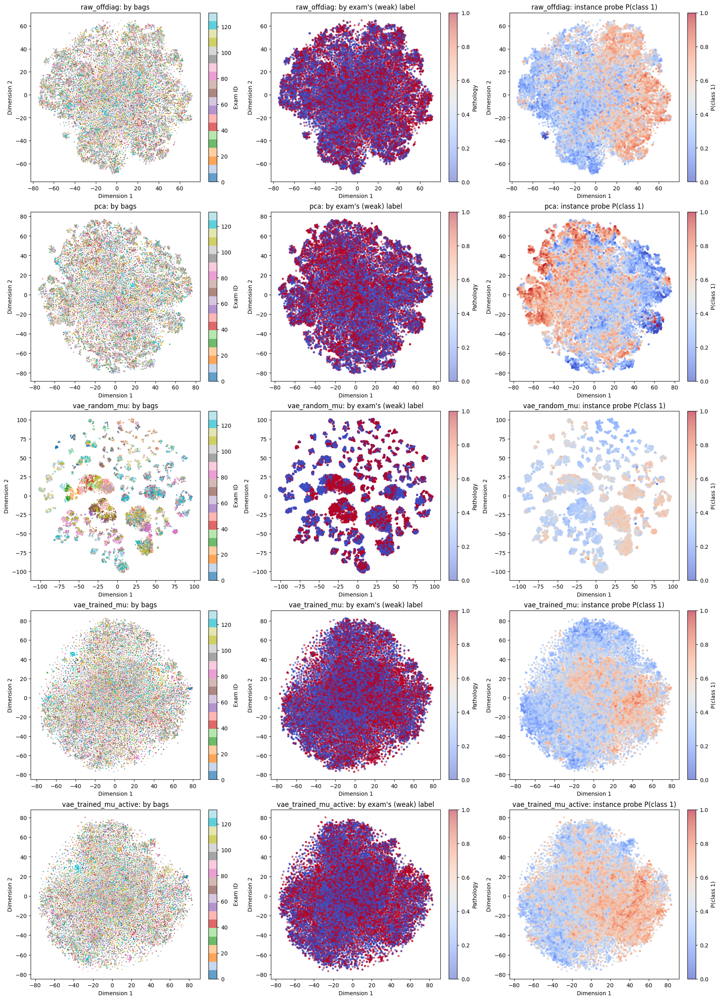

In [16]:
fig, axes = plot_embedding_votes(embeddings=embeddings_2d,
                                 artifacts=artifacts,
                                 exam_ids=exam_ids,
                                 window_labels=window_labels,
                                 rep_of=representations,
                                 mode="prob")
plt.show()

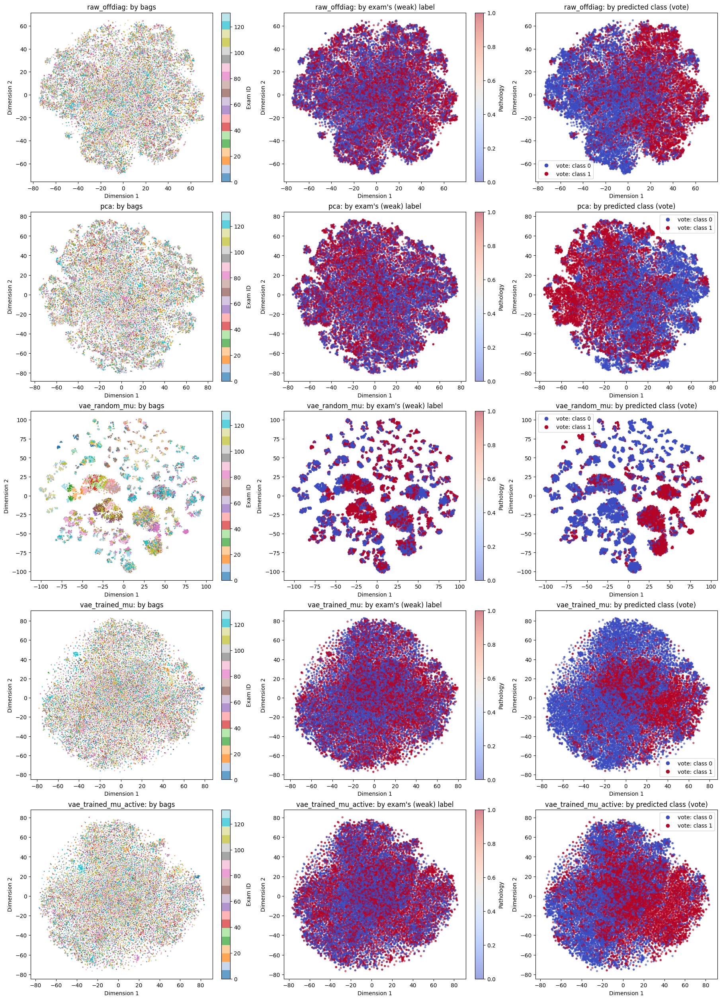

In [17]:
fig, axes = plot_embedding_votes(embeddings=embeddings_2d,
                                 artifacts=artifacts,
                                 exam_ids=exam_ids,
                                 window_labels=window_labels,
                                 rep_of=representations,
                                 mode="vote")
plt.show()